In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

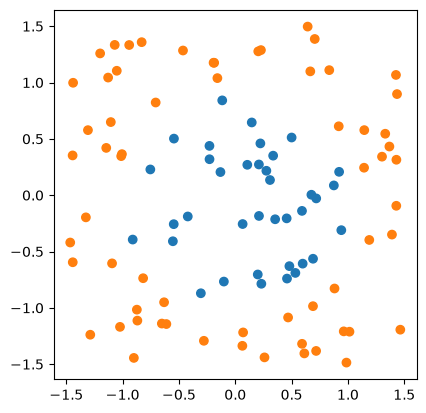

In [2]:
import random
from alexgpt.engine import Value, add, mul
from alexgpt.nn import MLP

np.random.seed(0)
random.seed(0)

num_points = 100
points = np.random.uniform(-1.5, 1.5, size=(num_points, 2))

labels = []
for i in range(num_points):
    x = points[i, 0]
    y = points[i, 1]
    if x * x + y * y < 1.0:
        labels.append(1.0)      # inside the circle
    else:
        labels.append(-1.0)     # outside the circle

point_colors = []
for label in labels:
    if label > 0:
        point_colors.append("tab:blue")
    else:
        point_colors.append("tab:orange")

plt.scatter(points[:, 0], points[:, 1], c=point_colors)
plt.gca().set_aspect("equal")
plt.show()

0 0.9167354490759786
20 0.4361605291128644
40 0.3010898657561251
60 0.22377678661542885
80 0.17737526770161735
100 0.14671066498993893
120 0.12492348548490194
140 0.10860797013410492
160 0.09588166234812118
180 0.08562801240768489


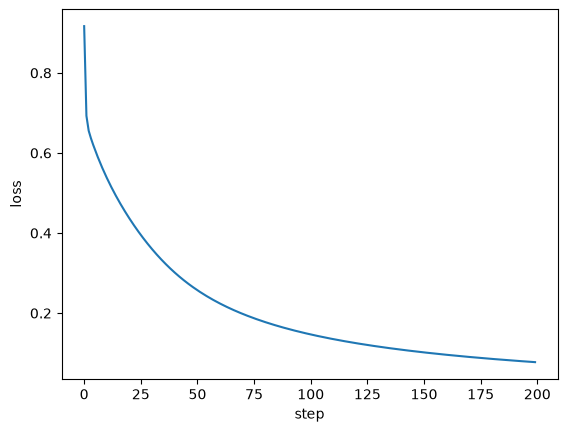

In [3]:
model = MLP(2, [8, 8, 1])
params = model.parameters()
learning_rate = 0.1
loss_history = []

for step in range(200):
    # 1. forward: loss over all points
    total_error = Value(0.0)
    for i in range(num_points):
        inputs = [Value(points[i, 0]), Value(points[i, 1])]
        prediction = model.forward(inputs)[0]
        error = add(prediction, Value(-labels[i]))           # prediction - label
        total_error = add(total_error, mul(error, error))    # += error²
    loss = mul(total_error, Value(1.0 / num_points))         # mean

    # 2. reset gradients
    for param in params:
        param.grad = 0.0

    # 3. backward
    loss.backward()

    # 4. update: small step against the gradient
    for param in params:
        param.data -= learning_rate * param.grad

    loss_history.append(loss.data)
    if step % 20 == 0:
        print(step, loss.data)

plt.plot(loss_history)
plt.xlabel("step")
plt.ylabel("loss")
plt.show()

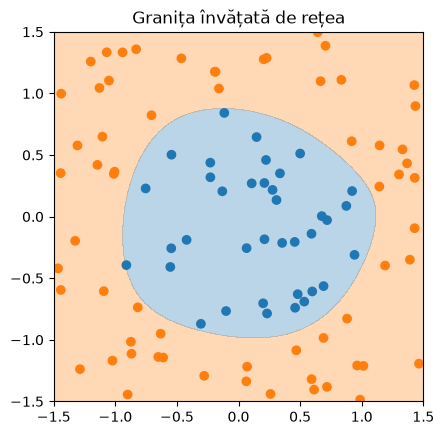

accuracy: 100 / 100


In [4]:
grid_size = 50
grid_values = np.linspace(-1.5, 1.5, grid_size)
predictions = np.zeros((grid_size, grid_size))

for row in range(grid_size):
    for col in range(grid_size):
        inputs = [Value(grid_values[col]), Value(grid_values[row])]
        predictions[row, col] = model.forward(inputs)[0].data

plt.contourf(grid_values, grid_values, predictions,
             levels=[-1, 0, 1], colors=["tab:orange", "tab:blue"], alpha=0.3)
plt.scatter(points[:, 0], points[:, 1], c=point_colors)
plt.gca().set_aspect("equal")
plt.title("Granița învățată de rețea")
plt.show()

correct = 0
for i in range(num_points):
    prediction = model.forward([Value(points[i, 0]), Value(points[i, 1])])[0].data
    if (prediction > 0) == (labels[i] > 0):
        correct += 1
print("accuracy:", correct, "/", num_points)

In [5]:
from alexgpt.tensor import Tensor, matmul, add_bias, tanh

rng = np.random.default_rng(0)
inputs = Tensor(rng.normal(size=(4, 3)))     # 4 examples, 3 features
weights = Tensor(rng.normal(size=(3, 5)))    # 3 inputs → 5 neurons
bias = Tensor(rng.normal(size=(5,)))

def layer_sum(w):
    return np.tanh(inputs.data @ w + bias.data).sum()

output = tanh(add_bias(matmul(inputs, weights), bias))
output.backward()

# numerical gradient for weights[1, 2]
h = 1e-6
w_plus = weights.data.copy();  w_plus[1, 2] += h
w_minus = weights.data.copy(); w_minus[1, 2] -= h
numeric = (layer_sum(w_plus) - layer_sum(w_minus)) / (2 * h)

print(weights.grad[1, 2], numeric)    # must be (almost) equal
print(weights.grad.shape)              # (3, 5)
print(bias.grad.shape)                 # (5,)
print(inputs.grad.shape)               # (4, 3)

-0.4570405938437284 -0.4570405947035283
(3, 5)
(5,)
(4, 3)
